# 01　QAM：发送与立即接收

本册把 **16QAM（16 点方阵）** 发出去再立刻整包抓回，落成 `mod_02_16QAM.npz`。
解调在 `02_QAM_demod`，判据在 `03_QAM_verify` —— 三本之间只靠 `.npz` 传递，任一本都能单独重跑。

| 项 | 值 |
|---|---|
| 调制 | 16QAM（I/Q 各 2 bit Gray，整体平均功率 1） |
| 载荷 | 每符号 4 bit，1024 bit × 9 帧 |
| 时长 | 25216 点 = 0.098 ms（9 帧 × 2688 点） |
| 帧结构 | `[64 符号 ZC 前导][载荷][16 符号零保护]`，9 帧首尾相接 |
| 成型 | RRC α=0.35、span=6，按**峰值** 0.4 归一（≈ −12 dBFS） |
| 硬件 | `v106/soc.bit` / RF 4096 MSPS / 字率 256 MHz / NCO 1000 MHz / 外部 SMA 环回 |

五个调制模块（AM / FM / ASK / PSK / QAM）共用一套库：`/home/xilinx/modulation/mod_dsp.py`
（星座、组帧、同步、锁相环）与 `mod_cases.py`（案例定义与接收机流水线）。
换调制只换 `Const` 这一层，**帧结构和同步代码不动** —— 这也是五种调制能共用一套接收链的原因。

## 1　导入与参数

`mod_dsp` 只依赖 QPSK 那边已经在板上验证过的 `qpsk_dsp`，本身不碰 pynq ——
所以解调册、校验册断电重启后也能直接跑。

`.npz` 一律落在库目录 `/home/xilinx/modulation/`，notebook 目录里只留 `.ipynb`。

In [1]:
import os
import sys

# 库目录：mod_dsp / mod_cases / 全部 .npz 都在这里（notebook 目录只放 .ipynb）
LIB  = "/home/xilinx/modulation"
QPSK = "/home/xilinx/qpsk"        # qpsk_dsp / qpsk_hw / qpsk_init / run_test
for _p in (LIB, QPSK):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

CASE = "16QAM"
N_TX, N_DEMOD, N_VERIFY = 1, 2, 3
# 抓包（第 N_TX 册写，第 N_DEMOD / N_VERIFY 册读）与指标（第 N_DEMOD 册写）
CAP_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_TX, CASE))
DEM_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_DEMOD, CASE))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

import mod_dsp as M
import mod_cases as C

# font.family 列表触发逐字形回退（mpl≥3.6）：拉丁取自 DejaVu，中文取本机
# 已有的 CJK 字体（板上 Droid Sans Fallback / Windows 雅黑）。只列**已安装**的
# 名字，否则 matplotlib 会为每个字形打一行 findfont 警告（实测上千行）。
import matplotlib.font_manager as _fm
_avail = {f.name for f in _fm.fontManager.ttflist}
_fam = [n for n in ("DejaVu Sans", "Microsoft YaHei", "Noto Sans CJK SC",
                    "WenQuanYi Zen Hei", "Droid Sans Fallback") if n in _avail]
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
    "font.family": _fam or ["DejaVu Sans"],
    "axes.unicode_minus": False,
})

SPEC = next(s for s in (C.DIGITAL_CASES + C.ANALOG_CASES) if s["name"] == CASE)
KIND = "digital" if "scheme" in SPEC else "analog"

print("mod_dsp  :", M.__file__)
print("mod_cases:", C.__file__)
print("案例     : %s（%s）" % (CASE, "数字" if KIND == "digital" else "模拟"))
print("库目录   :", LIB)
import qpsk_dsp as D

print("qpsk_dsp :", D.__file__)
print("抓包文件 :", CAP_NPZ)

mod_dsp  : /home/xilinx/modulation/mod_dsp.py
mod_cases: /home/xilinx/modulation/mod_cases.py
案例     : 16QAM（数字）
库目录   : /home/xilinx/modulation
qpsk_dsp : /home/xilinx/qpsk/qpsk_dsp.py
抓包文件 : /home/xilinx/modulation/mod_01_16QAM.npz


## 2　生成 16QAM 基带

组帧：`[64 符号 ZC 前导][载荷][16 符号零保护]`，RRC 成型（α=0.35，span=6），
9 帧首尾相接，前后各留 64 个符号的静默。

**归一化按峰值 0.4（≈ −12 dBFS）**：ASK/16QAM 的峰均比随图样变化，按 RMS 归一
会让某些图样削顶。

In [2]:
const, frames, fsyms, bb, lead, spf = C.build_digital(SPEC)
words = D.to_words(bb)

bps = const.k * (2 if const.scheme == "qam" else 1)
print("案例 %s：M = %d 点，每符号 %d bit，%d 帧 × %d bit"
      % (CASE, const.M, bps, len(frames), SPEC["n_bits"]))
print("每帧符号数：载荷 %d + 前导 %d + 保护 %d = %d"
      % (len(fsyms[0]), M.N_PRE, M.GUARD_SYM,
         len(fsyms[0]) + M.N_PRE + M.GUARD_SYM))
print("突发 %d 点 = %.1f µs（字率 256 MHz），帧数 %d"
      % (len(bb), len(bb) / 256e6 * 1e6, len(frames)))
print("峰值 %d LSB（%.0f%% 满量程），PAPR %.2f dB，削顶 %d 点（必须为 0）"
      % (int(np.max(np.abs(bb)) * 32767),
         100 * float(np.max(np.abs(bb))),
         20 * np.log10(np.max(np.abs(bb)) / np.sqrt(np.mean(np.abs(bb) ** 2))),
         int(np.sum(np.abs(bb) * 32767 >= 32767))))
print()
print("前 9 帧的图样：", ", ".join(t for t, _ in frames))

案例 16QAM：M = 16 点，每符号 4 bit，9 帧 × 1024 bit
每帧符号数：载荷 256 + 前导 64 + 保护 16 = 336
突发 25216 点 = 98.5 µs（字率 256 MHz），帧数 9
峰值 13106 LSB（40% 满量程），PAPR 6.03 dB，削顶 0 点（必须为 0）

前 9 帧的图样： rand, zeros, ones, alt, aa, 55, cnt, prbs9, onehot


**应该看到**：16 个星座点、每帧 256 载荷符号、突发约 94.5 µs、峰值 13107 LSB、削顶 0 点。

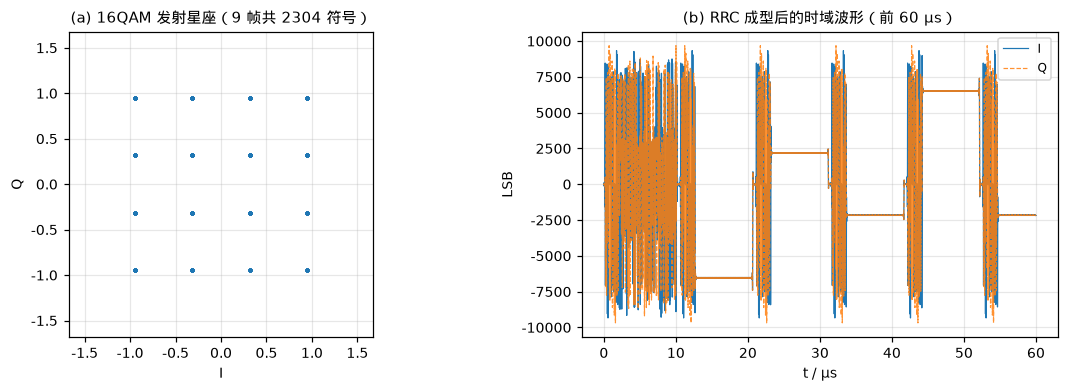

In [3]:
fig = plt.figure(figsize=(12.6, 3.6))
gs = fig.add_gridspec(1, 2, wspace=0.26)

sy = np.concatenate(fsyms)
ax = fig.add_subplot(gs[0, 0])
ax.plot(sy.real, sy.imag, ".", ms=3.0, alpha=0.5)
lim = 1.25 * max(1.0, float(np.max(np.abs(sy))))
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
ax.set_xlabel("I"); ax.set_ylabel("Q")
ax.set_title("(a) %s 发射星座（%d 帧共 %d 符号）" % (CASE, len(fsyms), len(sy)))

ax = fig.add_subplot(gs[0, 1])
n = min(len(bb), int(60e-6 * 256e6))
t = np.arange(n) / 256e6 * 1e6
ax.plot(t, bb[lead:lead + n].real * 32767, lw=0.8, label="I")
ax.plot(t, bb[lead:lead + n].imag * 32767, lw=0.8, ls="--", alpha=0.85, label="Q")
ax.set_xlabel("t / µs"); ax.set_ylabel("LSB")
ax.set_title("(b) RRC 成型后的时域波形（前 60 µs）")
ax.legend(loc="upper right")
plt.show()

## 3　环境就绪：时钟、位流、RFDC、DMA

与 `00_QAM_init` 做的是同一件事，直接复用 —— **01 跑过时这里只承接（约 2 s）**，断电重启后它也会把整条链自建一遍：

| 动作 | 函数 | 说明 |
|---|---|---|
| LMK 256 MHz + SYSREF | `qpsk_init.ensure_clock()` | 已锁定时 ~0.2 s 返回，不重写寄存器 |
| 位流 `v106/soc.bit` | `run_test.open_clean_loopback()` | PL 里已是 v106 就只解析 hwh，不重下 |
| RFDC 4096 MSPS + NCO 1000 MHz | 同上 | 同进程内已 init 过就不再 StartUp |
| 环回自检 | 同上 | 打一发 QPSK 探针，波峰因数 < 2.5 才算干净 |

**为什么用 QPSK 探针而不是本案例**：QPSK 那套自检已经在板上验证过，波峰因数阈值
（干净 ≈1.6，ADC 只回 I 通道时 ≥3.4）有明确实测依据。案例本身只用于测指标。

In [4]:
import time

import qpsk_init as QI
import run_test as R

clk = QI.ensure_clock()

probe = C.build_payload_set(1024, 9, 300)
h_q = D.rrc_filter(D.SPS)
probe_bb, _, _ = D.build_burst([b for _t, b in probe], h_q, D.SPS, peak=C.PEAK)

t_open = time.time()
lb, n_try, cf = R.open_clean_loopback(D.to_words(probe_bb), len(probe_bb))
print()
print("环回就绪：自检 %d 次，波峰因数 %.2f（阈值 %.1f），耗时 %.1f s"
      % (n_try, cf, R.CF_CLEAN, time.time() - t_open))
print("字率 %.3f MHz，RF %.1f MSPS" % (lb.fs_word / 1e6, lb.fs_rf))
st = lb.status()
for k in ("DAC", "ADC"):
    v = st[k]
    print("%s0 : enabled=%s  state=0x%X  PLL=%s"
          % (k, v.get("enabled"), v.get("state", 0), v.get("pll")))

  读回窗口自检通过（3 字节传输，rx[2] = 数据字节）

=== 配置四线 SPI readback ===
  SPI_LOCK 解锁 (R0x1FFD/R0x1FFE=0x00, R0x1FFF=0x53)
  R0x000 = 0x10 (SPI_3WIRE_DIS=1)
  R0x15F 无条件写回 0x13（写前读到 0x13，脏状态下该读数不可信）
  R0x16E = 0x3B (PLL2_LD_MUX=7 readback, TYPE=3 推挽)
  读回可信度检查通过（R0x171=0xAA / R0x172=0x02）
→ PLL2 已锁定、SYSREF 连续输出，跳过写表
  LMK 现状: 读回可信=True  PLL1 LD=0(0x00)  PLL2 LD=1(0x02)  SYSREF MUX=3
  [PASS] LMK 读回可信                                 R0x171=0xAA / R0x172=0x02
  [PASS] LMK PLL2 锁定（RFDC 时钟源）                 R0x183=0x02
  [PASS] SYSREF 连续输出（MUX=3）                     R0x139 MUX=3
  PLL1 LD=0（本板 PLL1 空载，LD=0 正常，不是故障）

 2　时钟
  结果  项目                                         实测 / 说明
  ----------------------------------------------------------------------------
  PASS  LMK 读回可信                                 R0x171=0xAA / R0x172=0x02
  PASS  LMK PLL2 锁定（RFDC 时钟源）                 R0x183=0x02
  PASS  SYSREF 连续输出（MUX=3）                     R0x139 MUX=3
  --------------------------------------------------------

  overlay 承接 1059 ms，5 个 IP
  DAC0 NCO 已是 1000.000 MHz，沿用
  ADC0 NCO 已是 1000.000 MHz，沿用


  环回自检  0（首次建立）：波峰因数 1.65  OK

环回就绪：自检 1 次，波峰因数 1.65（阈值 2.5），耗时 2.3 s
字率 256.000 MHz，RF 4096.0 MSPS
DAC0 : enabled=True  state=0xF  PLL=1
ADC0 : enabled=True  state=0xF  PLL=1


**应该看到**：`PLL2 LD=1`、`SYSREF MUX=3`、`波峰因数 < 2.5`、`DAC0 state=0xF`、`ADC0 enabled=1`。

**不对怎么查**：

| 现象 | 处置 |
|---|---|
| `PLL2 LD=0` | `QI.ensure_clock(force=True)` 重写 LMK 表 |
| 波峰因数 ≥ 3 | ADC 只回了 I 通道；`open_clean_loopback` 会自动 `rf_reinit()`，连续失败再查环回线 |
| `DAC state≠0xF` | 回 `00_QAM_init` 第 4 节（RFDC 与 NCO） |

## 4　收发并落盘

时序与 `qpsk/01_qpsk_tx_rx` 一致：**先挂接收、再启动发送**，这样突发完整落在 16.38 ms 的接收窗里。
一次 `lb.loop(words)` 同时完成 MM2S 发送与 S2MM 整包接收。

落盘只存突发前后各 64k 点的一段（整包 4.19 M 字里 98% 是静默），存的是**原始字**，
`02_QAM_demod` 可以据此把接收机每一步重算一遍。

In [5]:
t0 = time.time()
G = lb.loop(words)
dt = time.time() - t0

x = D.from_words(G["w"])
n = int(G["n"])
x = x[:n] if n else x
a, e = D.find_active(x)

C.save_capture(CAP_NPZ, CASE, x, len(bb), lb.fs_word,
               extra=dict(case_kind="digital", scheme=SPEC["scheme"],
                          k=SPEC["k"], n_bits=SPEC["n_bits"],
                          frames=SPEC["frames"], seed=C.SEED))

print("%s 收 %d 字（%.2f ms）  活跃区 [%d, %d) 长度 %d"
      % (CASE, n, n / lb.fs_word * 1e3, a, e, e - a))
print("TX %s  GAP %.0f µs  墙钟 %.0f ms"
      % ("完成" if G["tx_ok"] else "未完成", G["gap_us"], dt * 1e3))
print("已存 %s（%.2f MB）" % (CAP_NPZ, os.path.getsize(CAP_NPZ) / 1e6))

16QAM 收 4194299 字（16.38 ms）  活跃区 [19456, 46080) 长度 26624
TX 完成  GAP 77 µs  墙钟 264 ms
已存 /home/xilinx/modulation/mod_01_16QAM.npz（0.25 MB）


**应该看到**：`TX 完成`，GAP 几十 µs，接收 4 194 303 字（≈16.38 ms），活跃区约 43k 点。

## 5　小结

下一册 `02_QAM_demod` 只读这个 `.npz`，不碰硬件。

In [6]:
p = CAP_NPZ
print("%-6s %-6s %10s  %s" % ("案例", "类型", "文件 MB", "文件"))
print("-" * 78)
print("%-6s %-6s %10.2f  %s"
      % (CASE, "数字" if KIND == "digital" else "模拟",
         os.path.getsize(p) / 1e6, p))
print()
print("下一步：打开 %02d_%s_demod.ipynb（解调）→ %02d_%s_verify.ipynb（判定）"
      % (N_DEMOD, "QAM", N_VERIFY, "QAM"))

案例     类型          文件 MB  文件
------------------------------------------------------------------------------
16QAM  数字           0.25  /home/xilinx/modulation/mod_01_16QAM.npz

下一步：打开 02_QAM_demod.ipynb（解调）→ 03_QAM_verify.ipynb（判定）
